In [1]:
#| include: false
# Disable tqdm progress bars so they do not appear in the stored outputs
import os

os.environ["TQDM_DISABLE"] = "1"

# Convert coordinates from the Allen CCF or a registration tool

Histology registration tools such as those used to place probe tracks or labelled cells in the Allen Common Coordinate Framework (CCF) report positions in CCF micrometres. This page takes a small set of such points and converts them to the IBL frame, looks up the brain region at each one, plots them on a coronal slice, and converts them back.

How to cite this: see [Citations](../citations.qmd).

## The two frames

CCF coordinates are in micrometres from a corner of the atlas volume. IBL coordinates are in metres from bregma. Both describe the same volume; see [Atlas spaces and transforms](../explanation/atlas-spaces.qmd) for how they differ.

## Example points

Each row below is one point in CCF micrometres, ordered **(ML, AP, DV)**. This is `ccf_order='mlapdv'`, the default for the conversion functions. The Allen volume files order their axes **(AP, DV, ML)**, which is `ccf_order='apdvml'`: pass that if your points are stored that way. The numbers are the same either way and only the column order changes.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from iblatlas.atlas import AllenAtlas

ba = AllenAtlas()

# CCF micrometres, columns (ML, AP, DV); the five points share one coronal plane
ccf = np.array([[4239, 6000, 1500],
                [7239, 6000, 1500],
                [4739, 6000, 4000],
                [6739, 6000, 4000],
                [5739, 6000, 5500]], dtype=float)

## Convert to IBL coordinates

`AllenAtlas.ccf2xyz` returns metres relative to bregma, ordered (ML, AP, DV). ML counts to the right in both frames. AP and DV count the other way in the CCF: AP increases towards the back of the brain and DV increases downwards, so a larger CCF value is a more negative IBL value. Bregma is at CCF `(5739, 5400, 332)` µm, and converts to the origin.

In [3]:
xyz = ba.ccf2xyz(ccf)
print(np.round(xyz * 1e6))  # micrometres relative to bregma

bregma_ccf = np.array([[5739, 5400, 332]], dtype=float)
print(ba.ccf2xyz(bregma_ccf))

[[-1500.  -600. -1168.]
 [ 1500.  -600. -1168.]
 [-1000.  -600. -3668.]
 [ 1000.  -600. -3668.]
 [    0.  -600. -5168.]]
[[0. 0. 0.]]


## Find the brain region

`AllenAtlas.get_labels` takes IBL coordinates in metres and returns the Allen region id at each point. `ba.regions.id2acronym` converts ids to acronyms. For points outside the brain, coarser regions and the other options, see [Find which brain region a coordinate is in](find-the-region-of-a-point.ipynb).

In [4]:
ids = ba.get_labels(xyz)
pd.DataFrame({"allen_id": ids, "acronym": ba.regions.id2acronym(ids)})

,allen_id,acronym
0,478,SSp-ll6a
1,1128,SSp-ll5
2,255,AV
3,255,AV
4,38,PVH


## Plot the points on a coronal slice

`plot_cslice` takes the AP coordinate of the slice in metres, and draws it in micrometres, so the points are scattered in micrometres too.

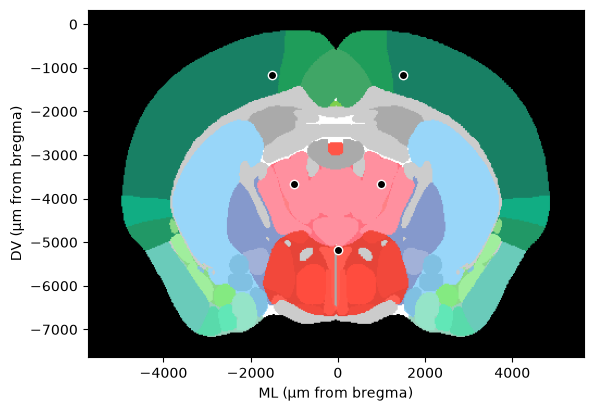

In [5]:
fig, ax = plt.subplots()
ba.plot_cslice(xyz[0, 1], volume='annotation', ax=ax)
ax.scatter(xyz[:, 0] * 1e6, xyz[:, 2] * 1e6, c='k', edgecolor='w', zorder=3)
ax.set_xlabel('ML (µm from bregma)')
ax.set_ylabel('DV (µm from bregma)')
plt.show()

## Convert back to CCF coordinates

`AllenAtlas.xyz2ccf` is the inverse. The round trip returns the starting points.

In [6]:
ccf_back = ba.xyz2ccf(xyz)
print(ccf_back)
np.allclose(ccf_back, ccf)

[[4239. 6000. 1500.]
 [7239. 6000. 1500.]
 [4739. 6000. 4000.]
 [6739. 6000. 4000.]
 [5739. 6000. 5500.]]


True

## Scaled atlases

`AllenAtlas` is the unscaled CCF, built from fixed, extracted tissue. If your coordinates come from in vivo work, [Atlas spaces and transforms](../explanation/atlas-spaces.qmd) describes the Needles and MRI Toronto scalings, which are the same volume with different scale factors.